# Лабораторная работа: генератор синтетических временных рядов

**Тема:** разработка генератора синтетических временных рядов на Python в Jupyter Notebook.

**Цель работы:** получить практические навыки генерации синтетических временных рядов: реализовать генератор с фиксированным шагом 5 минут, настраиваемым числом точек, типом дисперсии, тренда и сезонности, сохранением в CSV и визуализацией через `matplotlib`.

**Описание работы программы.** Ряд строится как сумма трёх компонент и шума:

`value(t) = base + trend(t) + seasonality(t) + noise(t) * sigma(t)`

- **timestamp** — начиная с 00:00 текущего дня, каждая следующая точка +5 минут;
- **дисперсия** `variance`: `const`, `grow`, `decay`, `random`;
- **тренд** `trend`: `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down`, `random`;
- **сезонность** `seasonality`: `none`, `one` (период 1 час = 12 точек), `two` (1 час и 6 часов = 12 и 72 точки), `random`;
- **дополнительно:** нелинейные тренды, выбросы, пропуски, JSON с метаданными.

## 1. Импорт библиотек

In [ ]:
import os
import csv
import json
from datetime import datetime, date, time, timedelta

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## 2. Реализация генератора

In [ ]:
STEP = timedelta(minutes=5)          # фиксированный интервал
DEFAULT_N_POINTS = 1000

VARIANCE_MODES = ("const", "grow", "decay")
TREND_MODES = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
EXTRA_TREND_MODES = ("exp", "poly", "log")      # доп. задание: нелинейные тренды
SEASONALITY_MODES = ("none", "one", "two")

# Периоды сезонности в точках (шаг 5 минут)
PERIOD_1H = 12     # 1 час
PERIOD_6H = 72     # 6 часов

# Суммарное изменение тренда за весь ряд
TREND_DELTA = {"fast_up": 150.0, "slow_up": 30.0, "fast_down": -150.0, "slow_down": -30.0}


def make_timestamps(n_points, start=None):
    """Временные метки с шагом 5 минут, начиная с 00:00 текущего дня."""
    if start is None:
        start = datetime.combine(date.today(), time.min)
    return [start + i * STEP for i in range(n_points)]


def make_variance(mode, n_points):
    """Множитель стандартного отклонения шума sigma(t)."""
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "const":
        return np.ones(n_points)
    if mode == "grow":
        return 0.5 + 4.5 * t            # от 0.5 до 5
    if mode == "decay":
        return 5.0 - 4.5 * t            # от 5 до 0.5
    raise ValueError(f"Неизвестный режим дисперсии: {mode}")


def make_trend(mode, n_points):
    """Компонента тренда."""
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode in TREND_DELTA:
        return TREND_DELTA[mode] * t
    # дополнительные нелинейные тренды
    if mode == "exp":
        return 100.0 * (np.exp(3.0 * t) - 1.0) / (np.exp(3.0) - 1.0)
    if mode == "poly":
        return 100.0 * (t ** 3 - 1.5 * t ** 2 + t)
    if mode == "log":
        return 100.0 * np.log1p(20.0 * t) / np.log1p(20.0)
    raise ValueError(f"Неизвестный режим тренда: {mode}")


def make_seasonality(mode, n_points):
    """Компонента сезонности (синусоиды)."""
    i = np.arange(n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode == "one":
        return 10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
    if mode == "two":
        return (10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
                + 20.0 * np.sin(2 * np.pi * i / PERIOD_6H))
    raise ValueError(f"Неизвестный режим сезонности: {mode}")


def generate_time_series(n_points=DEFAULT_N_POINTS, variance="random", trend="random",
                         seasonality="random", base=100.0, noise_std=1.0, seed=None,
                         outliers=0, missing=0.0, start=None):
    """
    Генерация синтетического временного ряда.

    n_points    : количество точек (по умолчанию 1000)
    variance    : 'const' | 'grow' | 'decay' | 'random'
    trend       : 'none' | 'fast_up' | 'slow_up' | 'fast_down' | 'slow_down' | 'random'
                  (доп.: 'exp' | 'poly' | 'log')
    seasonality : 'none' | 'one' | 'two' | 'random'
    base        : базовый уровень ряда
    noise_std   : базовое стандартное отклонение шума
    seed        : зерно генератора случайных чисел (для воспроизводимости)
    outliers    : число выбросов (доп. задание)
    missing     : доля пропусков 0..1 (доп. задание)

    Возвращает (timestamps, values, params).
    """
    if n_points < 1:
        raise ValueError("n_points должно быть >= 1")

    rng = np.random.default_rng(seed)

    # random -> случайный выбор одного из режимов
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    timestamps = make_timestamps(n_points, start)

    noise = rng.normal(0.0, noise_std, n_points) * make_variance(variance, n_points)
    values = base + make_trend(trend, n_points) + make_seasonality(seasonality, n_points) + noise

    outlier_idx = []
    if outliers > 0:
        outlier_idx = rng.choice(n_points, size=min(outliers, n_points), replace=False)
        scale = np.std(values) * 3
        values[outlier_idx] += rng.choice([-1, 1], size=len(outlier_idx)) * scale
        outlier_idx = sorted(int(k) for k in outlier_idx)

    missing_idx = []
    if missing > 0:
        k = int(round(n_points * missing))
        missing_idx = rng.choice(n_points, size=k, replace=False)
        values[missing_idx] = np.nan
        missing_idx = sorted(int(k) for k in missing_idx)

    params = {
        "n_points": n_points, "step_minutes": 5,
        "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S"),
        "variance": variance, "trend": trend, "seasonality": seasonality,
        "base": base, "noise_std": noise_std, "seed": seed,
        "outliers": outlier_idx, "missing_count": len(missing_idx),
    }
    return timestamps, values, params

In [ ]:
def unique_path(path):
    """Если файл существует — добавляет суффикс _1, _2, ..."""
    if not os.path.exists(path):
        return path
    root, ext = os.path.splitext(path)
    k = 1
    while os.path.exists(f"{root}_{k}{ext}"):
        k += 1
    return f"{root}_{k}{ext}"


def save_csv(timestamps, values, directory="."):
    """Сохраняет ряд в ts_YYYYMMDD_HHMMSS.csv (заголовок: timestamp,value)."""
    os.makedirs(directory, exist_ok=True)
    name = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
    path = unique_path(os.path.join(directory, name))
    with open(path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["timestamp", "value"])
        for ts, v in zip(timestamps, values):
            writer.writerow([ts.strftime("%Y-%m-%d %H:%M:%S"),
                             "" if np.isnan(v) else f"{v:.6f}"])
    return path


def save_metadata(params, csv_path):
    """Доп. задание: метаданные генерации в JSON рядом с CSV."""
    path = os.path.splitext(csv_path)[0] + ".json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(params, f, ensure_ascii=False, indent=2)
    return path


def plot_time_series(timestamps, values, params=None, title=None, save_path=None, show=True):
    """Строит график; при указании save_path сохраняет его в PNG."""
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(timestamps, values, linewidth=1)
    if params is not None and params.get("outliers"):
        idx = params["outliers"]
        ax.scatter([timestamps[i] for i in idx], [values[i] for i in idx],
                   color="red", zorder=3, label="выбросы")
        ax.legend()
    if title is None and params is not None:
        title = (f"variance={params['variance']}, trend={params['trend']}, "
                 f"seasonality={params['seasonality']}, n={params['n_points']}")
    ax.set_title(title)
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        fig.savefig(save_path, dpi=150)
    if show:
        plt.show()
    else:
        plt.close(fig)

## 3. Демонстрация случайной генерации

Все три параметра заданы как `random`, количество точек — по умолчанию (1000).

{'n_points': 1000, 'step_minutes': 5, 'start': '2026-10-11 00:00:00', 'variance': 'grow', 'trend': 'slow_up', 'seasonality': 'one', 'base': 100.0, 'noise_std': 1.0, 'seed': None, 'outliers': [], 'missing_count': 0}
Первая точка: 2026-10-11 00:00:00 | Последняя: 2026-10-14 11:15:00 | Шаг: 0:05:00


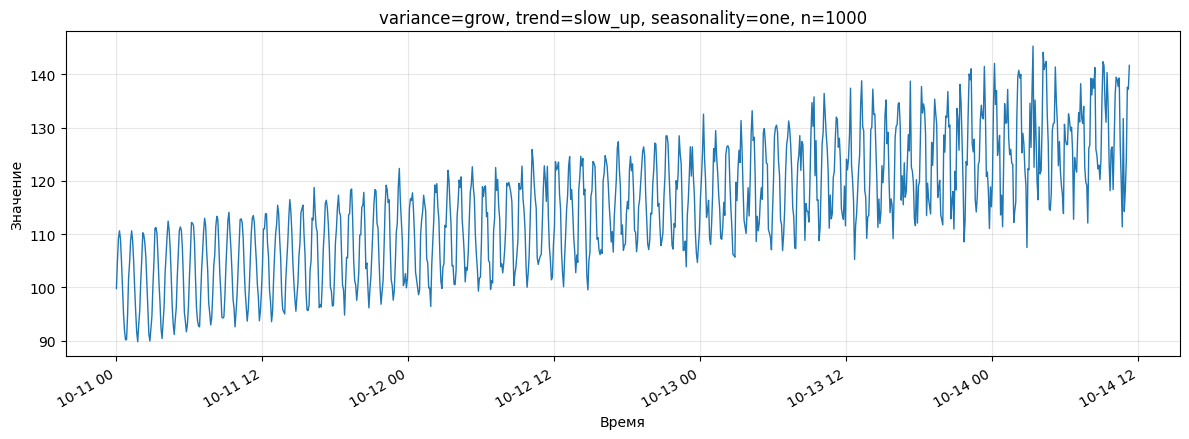

CSV сохранён: output/ts_20261011_165110.csv


In [ ]:
ts, vals, params = generate_time_series()          # variance/trend/seasonality = 'random'
print(params)
print("Первая точка:", ts[0], "| Последняя:", ts[-1], "| Шаг:", ts[1] - ts[0])

plot_time_series(ts, vals, params)

csv_path = save_csv(ts, vals, directory="output")
print("CSV сохранён:", csv_path)

In [ ]:
# Проверка начала CSV-файла
with open(csv_path, encoding="utf-8") as f:
    for _ in range(4):
        print(f.readline().rstrip())

timestamp,value
2026-10-11 00:00:00,99.777706
2026-10-11 00:05:00,104.985559
2026-10-11 00:10:00,109.225301


## 4. Описание работы программы и примеры вызова опций

### 4.1 Количество точек

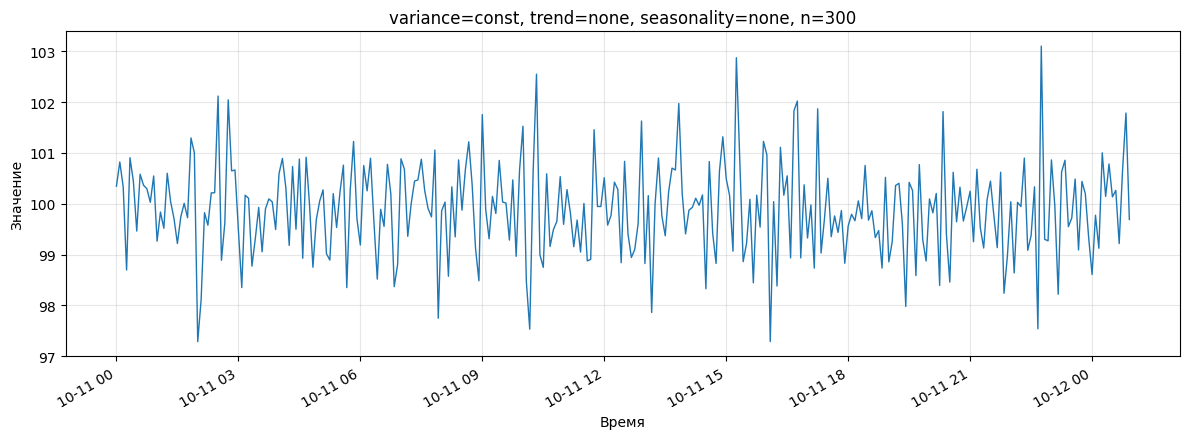

In [ ]:
ts, vals, p = generate_time_series(n_points=300, variance="const", trend="none", seasonality="none", seed=1)
plot_time_series(ts, vals, p)

### 4.2 Дисперсия: `const`, `grow`, `decay`

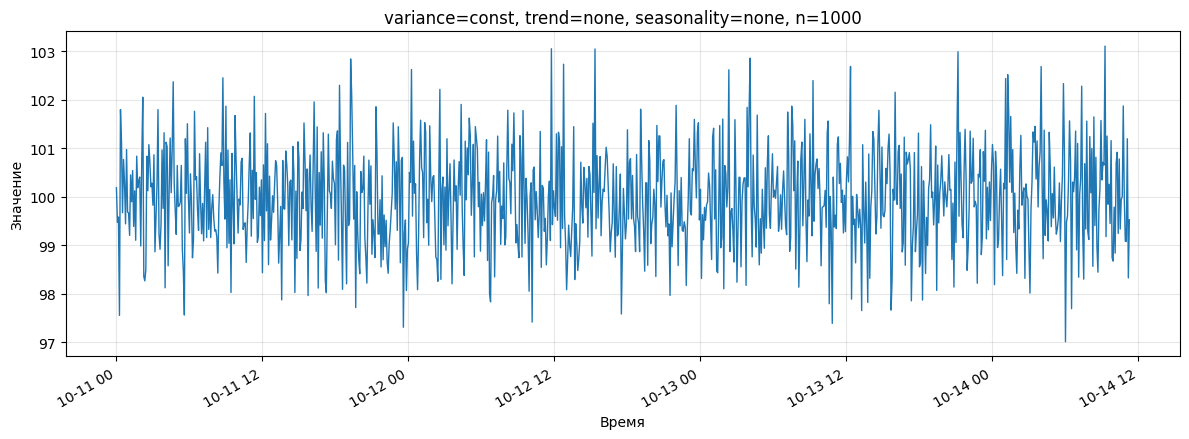

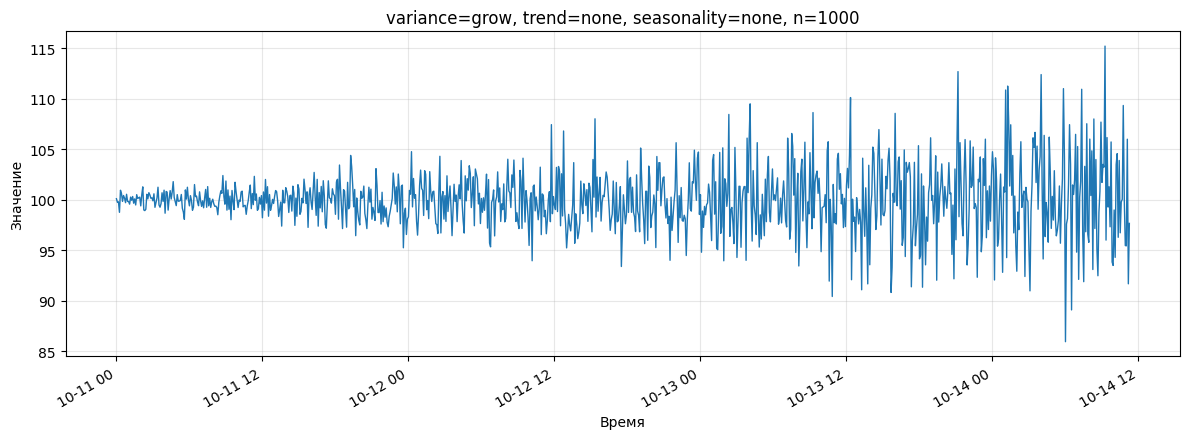

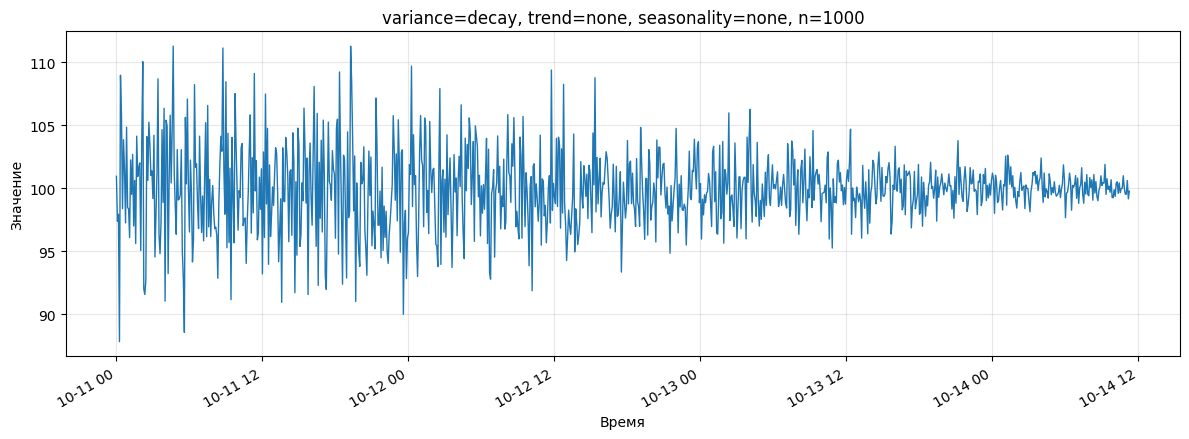

In [ ]:
for v in VARIANCE_MODES:
    ts, vals, p = generate_time_series(variance=v, trend="none", seasonality="none", seed=2)
    plot_time_series(ts, vals, p)

### 4.3 Тренд: `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down`

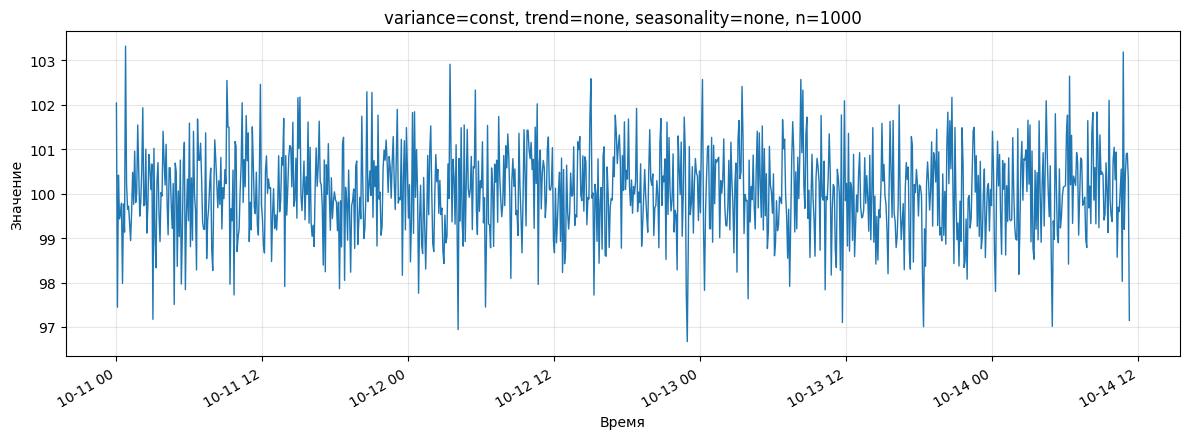

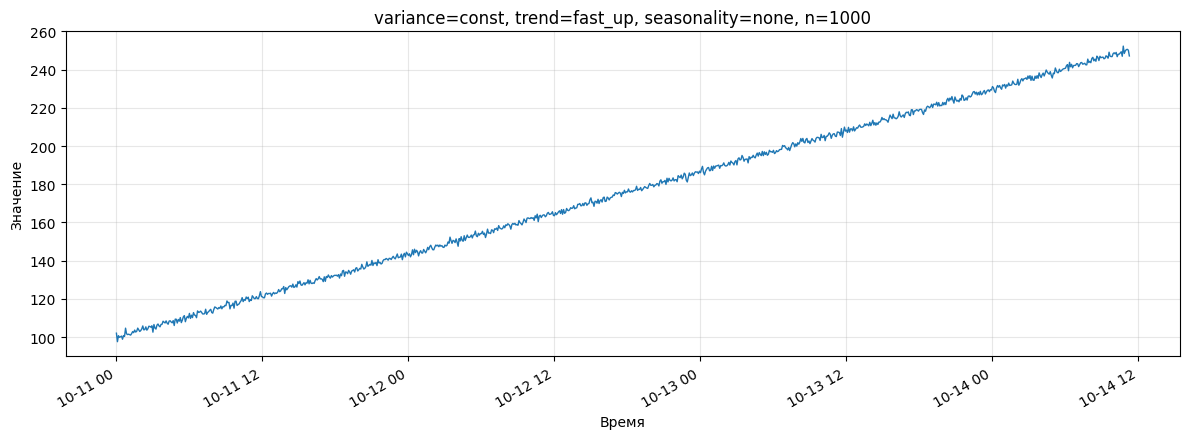

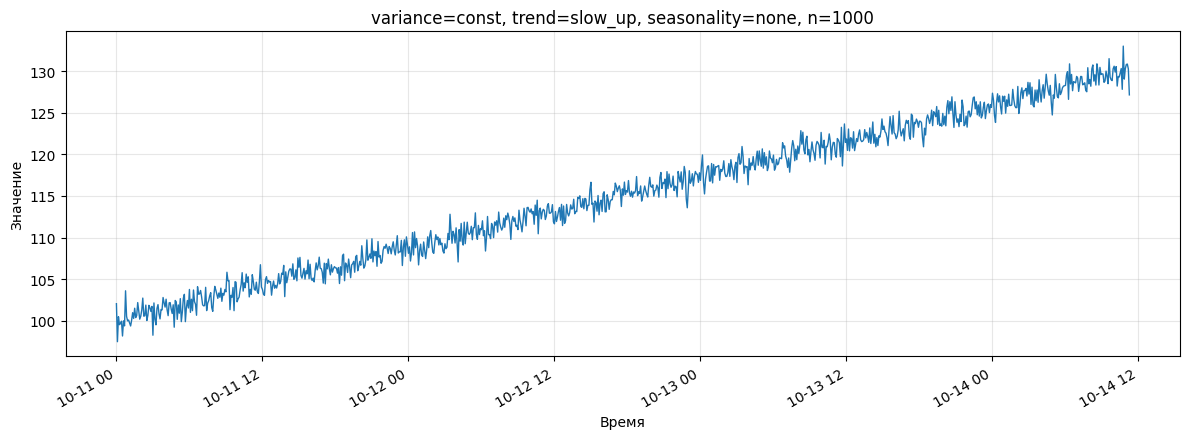

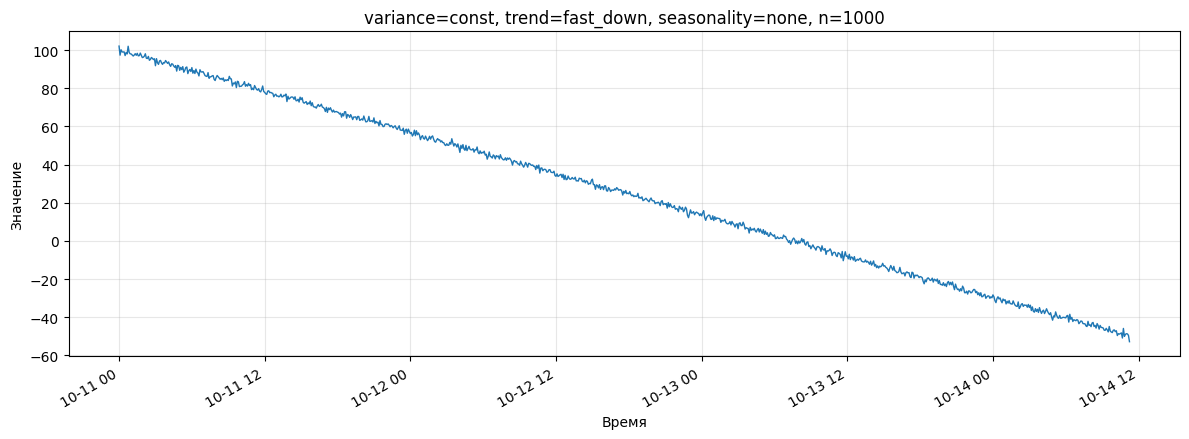

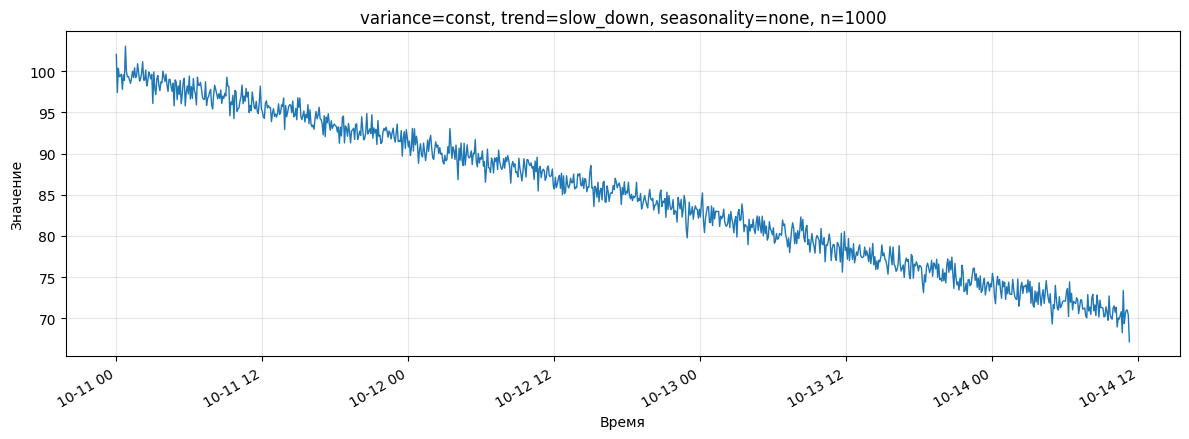

In [ ]:
for tr in TREND_MODES:
    ts, vals, p = generate_time_series(variance="const", trend=tr, seasonality="none", seed=3)
    plot_time_series(ts, vals, p)

### 4.4 Сезонность: `none`, `one` (1 час), `two` (1 час + 6 часов)

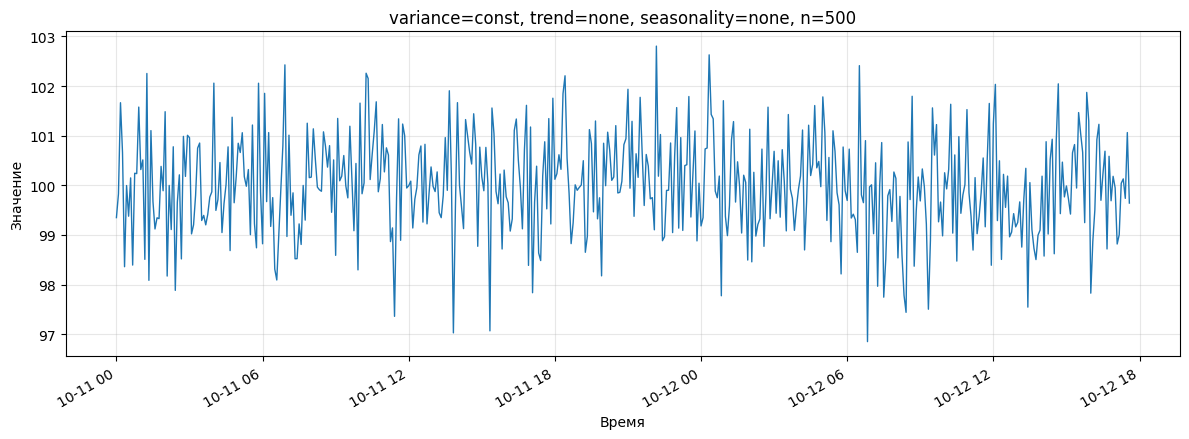

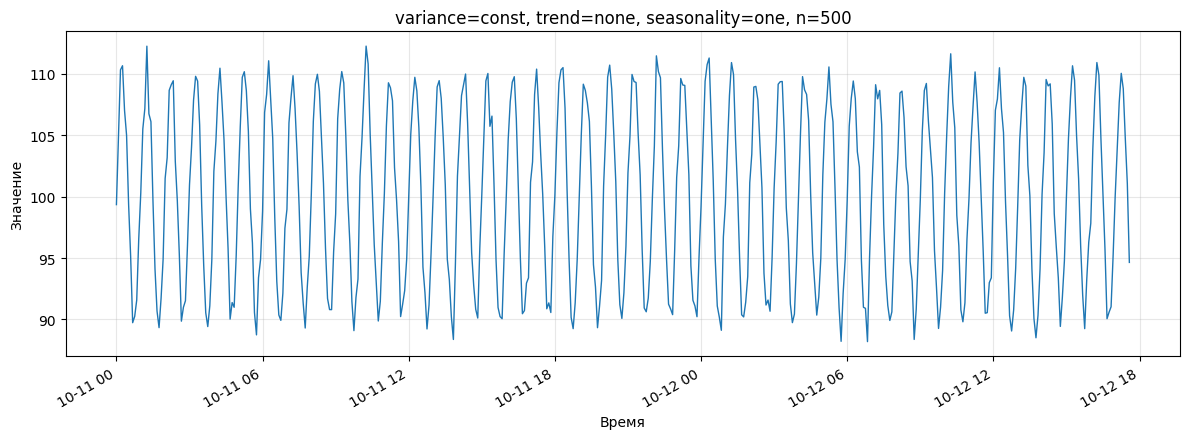

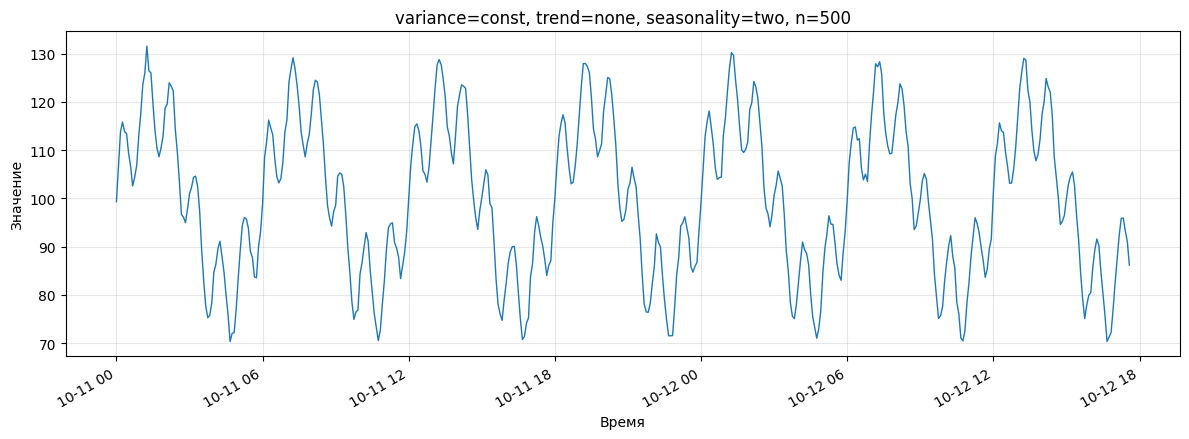

In [ ]:
for s in SEASONALITY_MODES:
    ts, vals, p = generate_time_series(n_points=500, variance="const", trend="none", seasonality=s, seed=4)
    plot_time_series(ts, vals, p)

### 4.5 Дополнительное задание: нелинейные тренды, выбросы, пропуски, JSON

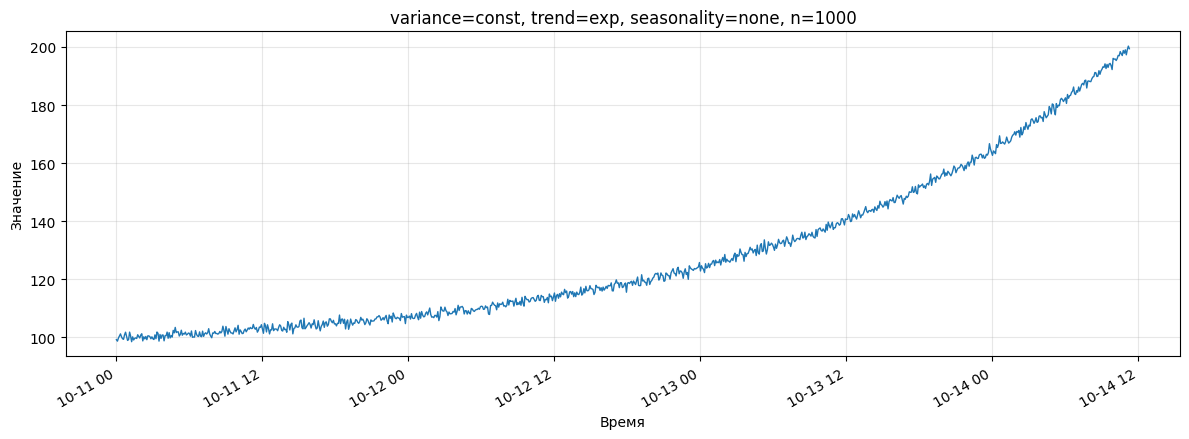

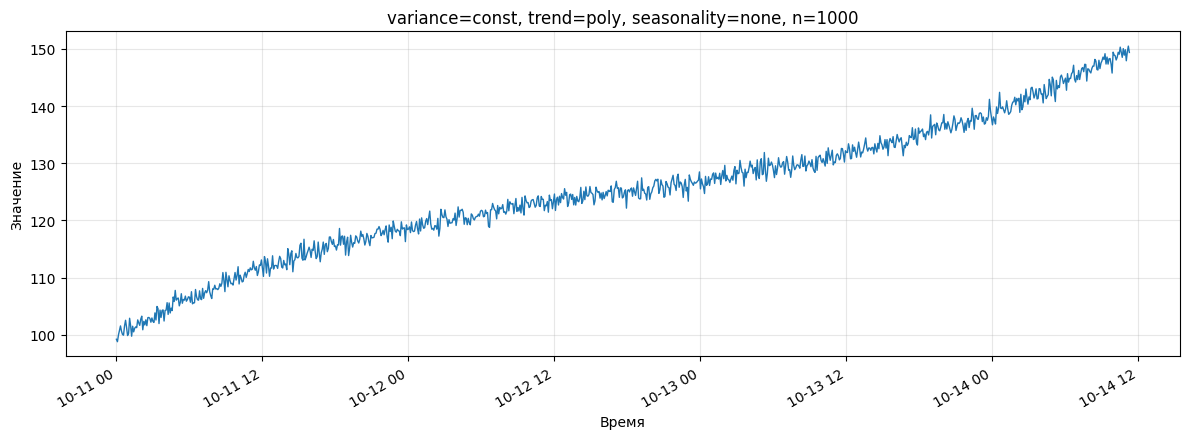

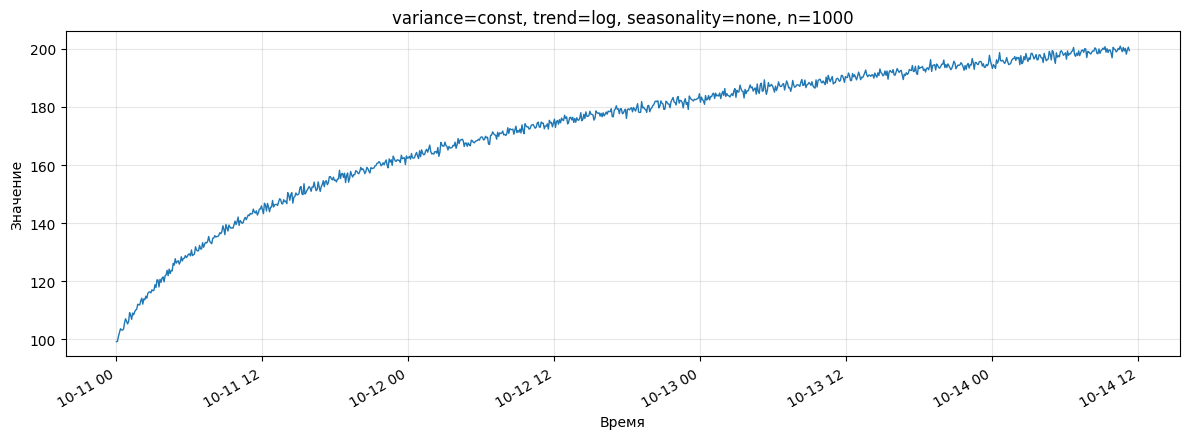

In [ ]:
for tr in EXTRA_TREND_MODES:
    ts, vals, p = generate_time_series(variance="const", trend=tr, seasonality="none", seed=5)
    plot_time_series(ts, vals, p)

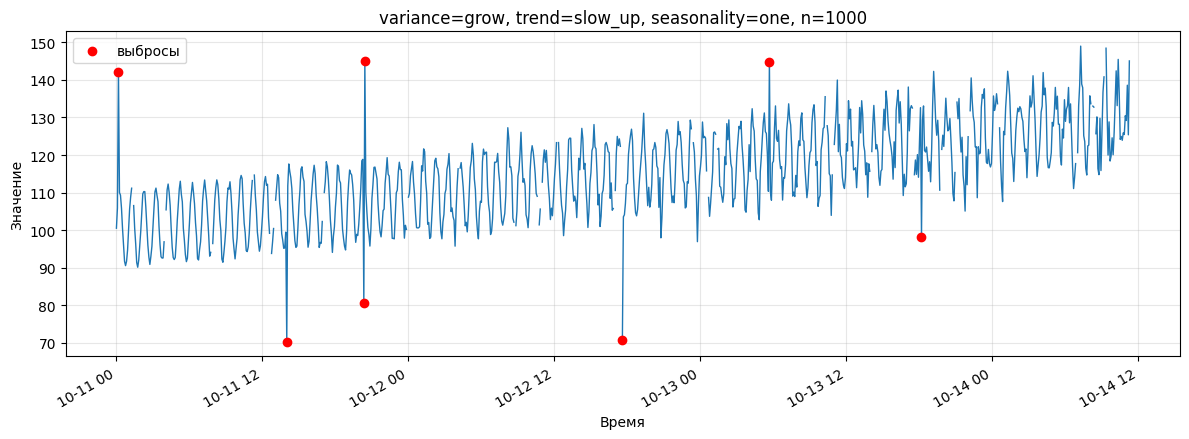

output/ts_20261011_165735.csv output/ts_20261011_165735.json
Пропусков (NaN): 30


In [ ]:
ts, vals, p = generate_time_series(variance="grow", trend="slow_up", seasonality="one",
                                   seed=6, outliers=8, missing=0.03)
plot_time_series(ts, vals, p)
csv_path = save_csv(ts, vals, directory="output")
json_path = save_metadata(p, csv_path)
print(csv_path, json_path)
print("Пропусков (NaN):", int(np.isnan(vals).sum()))

## 5. Три отчётных изображения

Изображения сохраняются в `images/lab_image_1.png`, `images/lab_image_2.png`, `images/lab_image_3.png`.

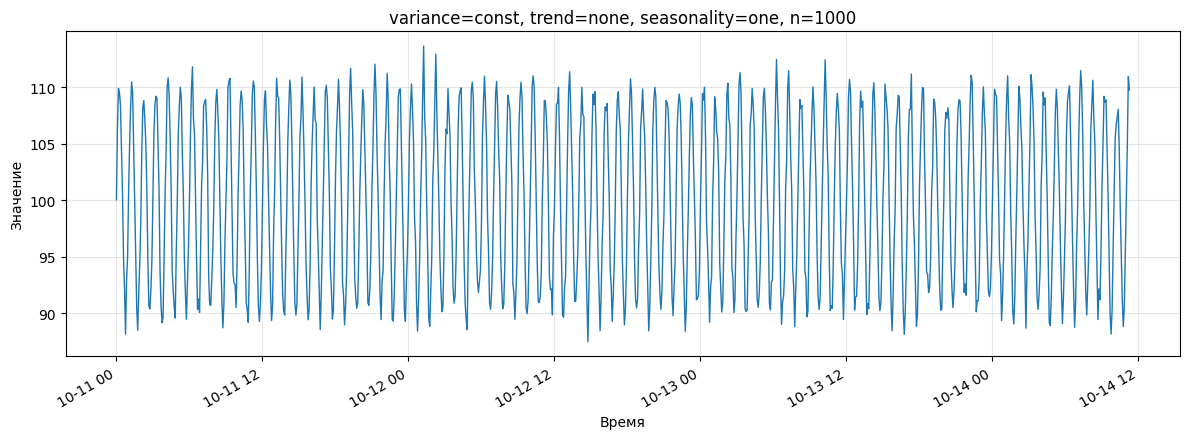

images/lab_image_1.png сохранён: {'n_points': 1000, 'step_minutes': 5, 'start': '2026-10-11 00:00:00', 'variance': 'const', 'trend': 'none', 'seasonality': 'one', 'base': 100.0, 'noise_std': 1.0, 'seed': 11, 'outliers': [], 'missing_count': 0}


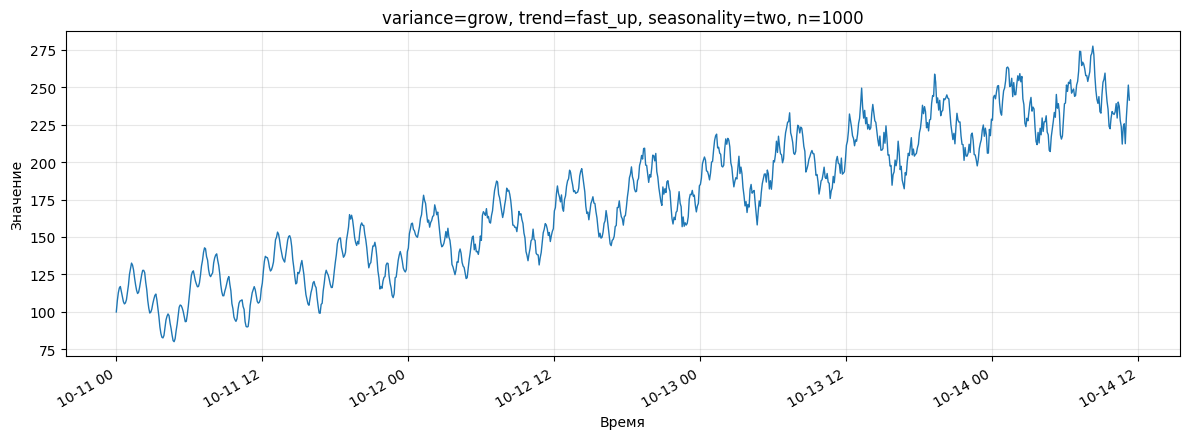

images/lab_image_2.png сохранён: {'n_points': 1000, 'step_minutes': 5, 'start': '2026-10-11 00:00:00', 'variance': 'grow', 'trend': 'fast_up', 'seasonality': 'two', 'base': 100.0, 'noise_std': 1.0, 'seed': 12, 'outliers': [], 'missing_count': 0}


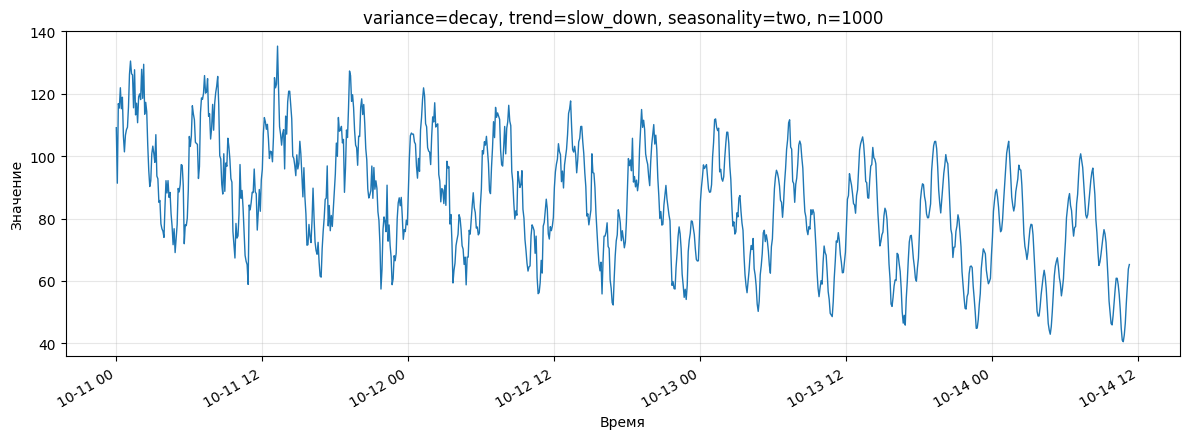

images/lab_image_3.png сохранён: {'n_points': 1000, 'step_minutes': 5, 'start': '2026-10-11 00:00:00', 'variance': 'decay', 'trend': 'slow_down', 'seasonality': 'two', 'base': 100.0, 'noise_std': 1.0, 'seed': 13, 'outliers': [], 'missing_count': 0}


In [ ]:
report_cases = [
    dict(variance="const", trend="none",      seasonality="one", seed=11),
    dict(variance="grow",  trend="fast_up",   seasonality="two", seed=12),
    dict(variance="decay", trend="slow_down", seasonality="two", seed=13),
]

for k, kwargs in enumerate(report_cases, start=1):
    ts, vals, p = generate_time_series(n_points=1000, **kwargs)
    plot_time_series(ts, vals, p, save_path=f"images/lab_image_{k}.png")
    print(f"images/lab_image_{k}.png сохранён:", p)

## Вывод

Реализован генератор временных рядов с шагом 5 минут и началом в 00:00 текущего дня. Поддерживаются режимы дисперсии, тренда и сезонности (включая `random`), сохранение в CSV и PNG. Выполнены дополнительные задания: нелинейные тренды, выбросы, пропуски и JSON-метаданные.